# Математички методи за машинско учење 2025/2026
## Домаћи задатак број 6

<div class="alert alert-block alert-danger">
<b>Име и презиме студента:</b> Jovan Paunović

<b>Број индекса:</b> 2122
    
</div>    

<div class="alert alert-block alert-info">
<b>Упутство за израду и предају домаћег задатака: </b> 
    
    1. Пре почетка израде промените име датотеке у 06Domaci_Ime_Prezime. (убаците своје име и презиме) 
    2. Попуните ћелију испод наслова одговарајућим подацима. 
    1. Употреба ћирилице није обавезна за предају домаћег задатка.
    4. За решавање задатака, уколико је потребно, отворите испод текста задатка додатне ћелије за уписивање текстуалног одговора (Markdown) или програмског кода (Code).
    1. Сва израчунавања, уколико је потребно, вршити у Python-у.
    5. Након завршетка израде решења домаћег Notebook документ сачувати у pdf формату и проследити га наставнику. То можете да урадите или кроз Teams или на мејл адресу jovana.dzunic@elfak.ni.ac.rs

</div> 

In [1]:
import numpy as np
import numpy.random as rndm
import matplotlib as mplb
import matplotlib.pyplot as plt

**Задатак 1.**  У анализи података, Фробенијусова норма мери укупну „енергију” матрице, док нуклеарна норма (норма трага) служи као конвексна апроксимација ранга (нпр. код *Matrix Completion* проблема). Спектрална норма, тј. норма индукована векторском $l_2$ нормом, користи се за процену стабилности алгоритама и нумеричких метода. Повезана је са доминантним структурама у подацима. 

| Норма        | Шта мери?                           | Математички еквивалент                 |
|--------------|--------------------------------------|-----------------------------------------|
| Нуклеарна    | Збир свих сингуарних вредности       | Апроксимација ранга                     |
| Фробенијусова| Квадратни корен збира квадрата       | Укупна енергија / Варијанса             |
| Спектрална   | Највећа сингуарна вредност           | Максимално истезање / Стабилност        |

Посматрајмо матрицу малог ранга $A_0 \in \mathcal{M}_{100 \times 100}$ (нпр. $r=5$) која је контаминирана адитивним Гаусовим шумом $\sigma E$, где су елементи $E_{ij} \sim \mathcal{N}(0, 1),$ тако да је резултујућа матрица $A = A_0 + \sigma E.$

**а)** 
1. Генерисати $A_0$ ранга 5 и шум $E$ тако да је $\|A_0\|_F \approx \sigma \|E\|_F$. Израчунати нуклеарну, Фробенијусову и спектралну норму за $A_0$ и $A$.
2. Проверити теоријску неједнакост: $\|A\|_2 \le \|A\|_F \le \|A\|_N$. 
3. Дискутовати: Која норма је најосетљивија на шум (највише расте релативно у односу на $A_0$)? Прокоментарисати у којим спектралним конфигурацијама су ове неједнакости „оштре” (sharp), а у којим случајевима су „лабаве”.
4. Како се мења спектрална норма $\|A\|_2$ (највећа сингуларна вредност) у односу на $\|A_0\|_2$? Објаснити зашто шум увек „надувава” спектар матрице.

(10 поена)

In [2]:
np.random.seed(42)

n = 100
r = 5

U = np.random.randn(n, r)
V = np.random.randn(r, n)
A0 = U @ V

E = np.random.randn(n, n)

norm_A0_F = np.linalg.norm(A0, 'fro')
norm_E_F = np.linalg.norm(E, 'fro')

sigma = norm_A0_F / norm_E_F

A = A0 + sigma * E

U0, S0, Vt0 = np.linalg.svd(A0)
A0_spec = S0[0]
A0_fro = np.linalg.norm(A0, 'fro')
A0_nuc = np.linalg.norm(A0, 'nuc')

U_A, S_A, Vt_A = np.linalg.svd(A)
A_spec = S_A[0]
A_fro = np.linalg.norm(A, 'fro')
A_nuc = np.linalg.norm(A, 'nuc')

print("Norme za A0")
print(f"Spektralna: {A0_spec:.2f}")
print(f"Frobenijusova: {A0_fro:.2f}")
print(f"Nuklearna: {A0_nuc:.2f}")

print("\nNorme za A (A0 + šum)")
print(f"Spektralna: {A_spec:.2f}")
print(f"Frobenijusova: {A_fro:.2f}")
print(f"Nuklearna: {A_nuc:.2f}")

print("\nProvera nejednakosti")
print(f"Za A0: {A0_spec:.2f} <= {A0_fro:.2f} <= {A0_nuc:.2f} -> {A0_spec <= A0_fro <= A0_nuc}")
print(f"Za A : {A_spec:.2f} <= {A_fro:.2f} <= {A_nuc:.2f} -> {A_spec <= A_fro <= A_nuc}")

print("\nRelativno povećanje usled šuma (A / A0)")
print(f"Nuklearna:    {A_nuc/A0_nuc:.2f}x")
print(f"Frobeniusova: {A_fro/A0_fro:.2f}x")
print(f"Spektralna:   {A_spec/A0_spec:.2f}x")

Norme za A0
Spektralna: 118.88
Frobenijusova: 216.48
Nuklearna: 474.50

Norme za A (A0 + šum)
Spektralna: 124.76
Frobenijusova: 306.93
Nuklearna: 2197.42

Provera nejednakosti
Za A0: 118.88 <= 216.48 <= 474.50 -> True
Za A : 124.76 <= 306.93 <= 2197.42 -> True

Relativno povećanje usled šuma (A / A0)
Nuklearna:    4.63x
Frobeniusova: 1.42x
Spektralna:   1.05x


Kao što vidimo iz rezultata, nuklearna norma najviše raste (povećava se preko $4.5$ puta). Matrica $A_0$ ima rang $r=5$, što znači da ima samo $5$ ne-nula singularnih vrednosti. Dodavanjem Gausovog šuma, preostalih 95 singularnih vrednosti (koje su bile nula) postaju pozitivne, i sve one zajedno drastično povećavaju zbir. Spektralna norma najmanje raste jer zavisi samo od najveće singularne vrednosti $\sigma_1$.

Što se tiče nejednakosti
$$
\|A\|_2 \leq \|A\|_F \leq \|A\|_N
$$

Kada matrica ima rang $1$ (ima jednu ne-nultu singularnu vrednost), sve tri norme se poklapaju:
$$
\|A\|_2 = \|A\|_F = \|A\|_N.
$$

Kada matrica ima veliki rang (mnogo singularnih vrednosti), razlike između normi postaju velike:
$$
\|A\|_2 \ll \|A\|_F \ll \|A\|_N.
$$

To možemo da vidimo i pomoću sledećeg Python koda:

In [3]:
def matrix_norms(M):
    s = np.linalg.svd(M, compute_uv=False)
    return np.max(s), np.linalg.norm(M, 'fro'), np.sum(s)

np.random.seed(42)
# Rang 1
u = np.random.randn(100,1)
v = np.random.randn(100,1)
A_1 = u @ v.T

# Rang 100
I = np.eye(100)

print("Rang 1 matrica:")
print(matrix_norms(A_1))

print("\nRang 100 matrica:")
print(matrix_norms(I))

Rang 1 matrica:
(np.float64(86.33131566963837), np.float64(86.33131566963836), np.float64(86.3313156696384))

Rang 100 matrica:
(np.float64(1.0), np.float64(10.0), np.float64(100.0))


Spektralna norma matrice $A$ se relativno malo povećala u odnosu na spektralnu normu matrice $A_0$. 
Šum dodaje nove komponente u svim pravcima tj. dodavanje šuma uvek povećava spektar, jer se pojavljuje nova dominantna vrednost. Zbog toga šum uvek "naduvava" spektar matrice.

**б)** 
1. Применити SVD на матрицу $A$. Конструисати серију најбољих апроксимација $A_k$ за $k=1, \dots, 20$. 
2. Нацртати график функције грешке апроксимације $f(k) = \|A - A_k\|_F$. 
3. Пронаћи „колено” (elbow) на графику и повезати га са стварним рангом матрице $A_0$. Дискутовати како интензитет шума $\sigma$ утиче на заобљеност колена и зашто је ова метода често субјективна.

(5 поена)

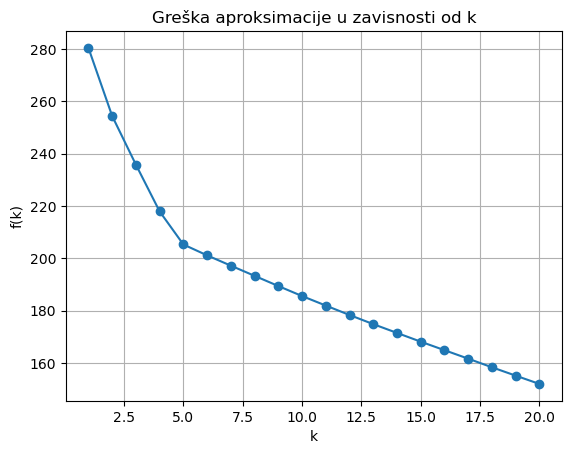

In [4]:
U, S, Vt = np.linalg.svd(A)

errors = []
for k in range(1, 21):
    Ak = (U[:, :k] * S[:k]) @ Vt[:k, :]
    errors.append(np.linalg.norm(A - Ak, 'fro'))

plt.plot(range(1, 21), errors, marker='o')
plt.xlabel("k")
plt.ylabel("f(k)")
plt.title("Greška aproksimacije u zavisnosti od k")
plt.grid(True)
plt.show()

Sa grafika vidimo da greška brzo opada do $k=5$, nakon čega opada slabije. To mesto na grafiku je "koleno" i ono se poklapa sa stvarnim rangom matrice $A_0$ (njen rang je $5$).

Kada postoji mali šum (malo $\sigma$) onda je koleno oštro i jasno definisano. Ako postoji veliki šum (veliko $\sigma$) onda je koleno više zaobljeno i teže se uočava. To je zbog toga što u tom slučaju singularne vrednosti šuma postaju uporedive sa singularnim vrednostima matrice $A_0$.

Ova metoda je često subjektivna zato što zavisi od vizuelne procene i intenziteta šuma. Kada podaci poseduju dosta šuma, onda se koleno ne vidi jasno i ne postoji strogo definisan matematički kriterijum koji određuje gde se koleno tačno nalazi na grafiku, već to mora odokativno da se odredi.

***

**в) Marchenko-Pastur закон и оптимални праг за PCA:**

Теорија случајних матрица нуди прецизније решење за раздвајање сигнала од шума. За квадратну матрицу димензија $n \times n$ чији су елементи $N(0, \sigma^2)$, Marchenko-Pastur закон предвиђа да ће се сингуларне вредности „чистог шума” налазити унутар опсега чија је горња граница (тзв. *edge*):
$$\lambda_{max} \approx 2 \sigma \sqrt{n}$$
Све сингуларне вредности изнад овог прага сматрају се релевантним сигналом.

1. Извршити SVD матрице $A$. Нацртати хистограм свих сингуларних вредности.
2. На истом графику означити теоријски Marchenko-Pastur праг. 
3. Израчунати нумерички ранг матрице $A$ користећи овај праг. Упоредити добијени број са стварним рангом $A_0$.
4. **Деноисинг:** Конструисати апроксимацију $\tilde{A}$ задржавајући само сингуларне вредности изнад MP прага. Израчунати релативну грешку $\|\tilde{A} - A_0\|_F / \|A_0\|_F$. Дискутовати зашто је ово решење робусније од фиксирања броја компоненти „на слепо”.

(10 поена)

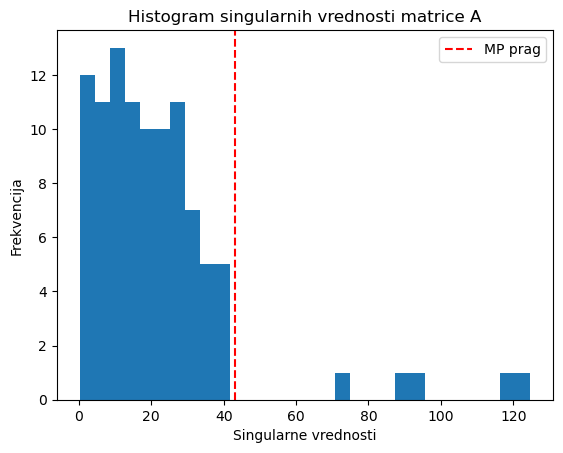

Numerički rang: 5
Stvarni rang A0: 5
Relativna greška: 0.3282970311160851


In [5]:
U, S, Vt = np.linalg.svd(A)

plt.hist(S, bins=30)
lambda_max = 2 * sigma * np.sqrt(n)
plt.axvline(lambda_max, color='red', linestyle='--', label='MP prag')
plt.xlabel("Singularne vrednosti")
plt.ylabel("Frekvencija")
plt.title("Histogram singularnih vrednosti matrice A")
plt.legend()
plt.show()

r_num = np.sum(S > lambda_max)
print("Numerički rang:", r_num)
print("Stvarni rang A0:", r)

keep = S > lambda_max
At = U[:, keep] @ np.diag(S[keep]) @ Vt[keep, :]
rel_error = np.linalg.norm(At - A0, 'fro') / np.linalg.norm(A0, 'fro')
print("Relativna greška:", rel_error)

Dobijeni numerički rang se poklapa sa stvarnim rangom. Na histogramu vidimo veliku gomilu malih singularnih vrednosti koje se nalaze sa leve strane MP praga i to su singularne vrednosti koje potiču od šuma. Desno od MP praga imamo izolovane i značajno veće singularne vrednosti i one se smatraju korisnim signalom.

Ovo rešenje je robusnije od fiksiranja broja komponenti "na slepo" jer ako unapred fiksiramo broj komponenti, rizikujemo da pogrešno odsečemo signal ili da uključimo šum. Pomoću Marchenko-Pastur zakona, određujemo prag koji adaptivno razdvaja signal od šuma, pa je metoda stabilnija i manje subjektivna.

***

**Задатак 2.**  Кондициони број и стабилност линеарне регресије

У машинском учењу, проблем најмањих квадрата $\|Ax - b\|_2$ постаје нумерички нестабилан ако су колоне матрице $A$ скоро линеарно зависне (феномен мултиколинеарности). Овај задатак истражује границе машинске тачности кроз призму спектралне декомпозиције.

**а)** Креирати матрицу података $A \in \mathcal{M}_{100 \times 10}$ где је првих 9 колона насумично генерисано из расподеле $\mathcal{N}(0,1)$. Десету колону дефинисати као линеарну комбинацију прве две уз додатак минималног шума: $A_{:, 9} = A_{:, 0} + A_{:, 1} + \epsilon$, где је $\epsilon \sim \mathcal{N}(0, 10^{-k})$. 
- Прокоментарисати како параметар $k$ утиче на утиче на линеарну зависност колона матрице $A.$

(5 поена)

In [6]:
np.random.seed(42)

n = 100
m = 10

A_base = np.random.randn(n, m-1)

k_values = [1, 3, 5, 8, 12, 15]

for k in k_values:
    A = np.zeros((n, m))
    
    A[:, :9] = A_base
    
    epsilon = np.random.randn(n) * (10.0**(-k))
    
    A[:, 9] = A[:, 0] + A[:, 1] + epsilon
    
    cond_A = np.linalg.cond(A)
    
    print(f"k: {k}, Nivo šuma: 1e-{k}, Kondicioni broj: {cond_A:.2e}")

k: 1, Nivo šuma: 1e-1, Kondicioni broj: 3.22e+01
k: 3, Nivo šuma: 1e-3, Kondicioni broj: 3.39e+03
k: 5, Nivo šuma: 1e-5, Kondicioni broj: 2.81e+05
k: 8, Nivo šuma: 1e-8, Kondicioni broj: 3.18e+08
k: 12, Nivo šuma: 1e-12, Kondicioni broj: 3.23e+12
k: 15, Nivo šuma: 1e-15, Kondicioni broj: 2.97e+15


Kako se $k$ povećava, tako je nivo šuma sve manji. Ako je $k$ malo, onda je šum veliki, pa poslednja kolona i nije baš linearna kombinacija prve dve kolone, a ako se $k$ dovoljno poveća, onda se šum dosta smanji pa je poslednja kolona matrice $A$ skoro linearna kombinacija prve dve kolone, što dovodi do fenomena multikolinearnosti.

To dalje uzrokuje da je kondicioni broj sve veći kako se $k$ povećava, a on nam direktno govori koliko je problem numerički stabilan. Ako je kondicioni broj veliki, onda je i problem prilično nestabilan. Dakle, povećanjem $k$ problem postaje sve nestabilniji.

**б)** Симулирати систем $Ax = b$ тако што ћете дефинисати тачно решење $x_{true} = [1, 1, \dots, 1]^T$ и израчунати десну страну као $b = A x_{true}$. Користећи функцију за решавање система (нпр. `np.linalg.solve`), израчунати нумеричко решење $\hat{x}$.
1. Упоредити грешке $\|\hat{x} - x_{true}\|_2$ за $k=2$ и $k=14$. 
2. Израчунати број изгубљених значајних цифара. 
3. Проверити важење процене: $\text{изгубљене цифре} \approx \log_{10}(\kappa(A))$. Повезати резултате са чињеницом да стандардна *float64* прецизност има око 15–17 значајних децималних цифара.

(10 поена)

In [18]:
n = 10
m = 10
np.random.seed(42)

A_base = np.random.randn(n, m-1).astype(np.float64)

x_true = np.ones(m, dtype=np.float64)

epsM = np.finfo(np.float64).eps
print(f"Mašinsko epsilon: {epsM:.2e}\n")

for k in [2, 14]:
    epsilon = np.random.randn(n).astype(np.float64) * (10**(-k))
    col10 = A_base[:,0] + A_base[:,1] + epsilon
    A = np.column_stack([A_base, col10])

    b = A @ x_true

    #x_hat, _, _, _ = np.linalg.lstsq(A, b, rcond=None) # ako se rešava problem najmanjih kvadrata
    x_hat = np.linalg.solve(A, b)

    error = np.linalg.norm(x_hat - x_true, 2)
    
    kappa = np.linalg.cond(A)

    lost_digits = np.log10(kappa)
    m = int(np.floor(-np.log10(2*kappa*epsM)))

    print(f"Rezultati za k={k}")
    print(f"Greška ||x_hat - x_true||_2: {error:.2e}")
    print(f"Kondicioni broj: {kappa:.2e}")
    print(f"Izgubljene cifre ≈ log10(κ(A)): {lost_digits:.2f}")
    print(f"Preostale cifre (16 - lost_digits): {16-lost_digits}")
    print(f"Značajne cifre ≈ {m}")
    print()

Mašinsko epsilon: 2.22e-16

Rezultati za k=2
Greška ||x_hat - x_true||_2: 1.27e-13
Kondicioni broj: 1.38e+03
Izgubljene cifre ≈ log10(κ(A)): 3.14
Preostale cifre (16 - lost_digits): 12.858642360673553
Značajne cifre ≈ 12

Rezultati za k=14
Greška ||x_hat - x_true||_2: 5.11e-02
Kondicioni broj: 7.64e+14
Izgubljene cifre ≈ log10(κ(A)): 14.88
Preostale cifre (16 - lost_digits): 1.11709297511565
Značajne cifre ≈ 0



Vidimo da data procena izgubljenih cifara važi. Za slučaj $k=2$, šum je veliki, poslednja kolona nije skoro linearna kombinacija prve dve kolone, kondicioni broj nije ogroman i sistem je stabilan. Procena pokazuje da je broj izgubljenih cifara oko 3, što kad se oduzme od 16 (jer je to otprilike broj značajnih cifara kod float64) daje nekih 12-13 značajnih cifara. To se poklapa sa brojem značajnih cifara izračunatih preko nejednačine  $\kappa(A)\epsilon_M\leq\dfrac12\cdot10^{-m}$. Dakle, u ovom slučaju greška je mala i imamo dosta značajnih cifara.

Kad je $k=14$, šum je mali pa poslednja kolona postaje skoro linearna kombinacija prve dve kolone matrice $A$. Kondicioni broj postaje ogroman i procena na osnovu kondicionog broja pokazuje da je gubitak značajnih cifara oko 14 ili 15. Ako to oduzmemo od 16 onda nam ostaje oko 1 značajna cifra u rezultatu. Broj značajnih cifara dobijen preko nejednačine $\kappa(A)\epsilon_M\leq\dfrac12\cdot10^{-m}$ je približno 0. Dakle i u ovom slučaju su procene broja značajnih cifara bliske, ali sada ukazuju da je rešenje nepouzdano.

**в)** На основу претходних резултата, написати кратак коментар (5–10 реченица) у коме се:

- објашњава зашто скоро линеарна зависност колона доводи до лоше кондиционираности,
- повезује параметар шума $k$ са геометријом колона матрице $A$,
- интерпретира значење кондиционог броја у контексту стабилности линеарне регресије,
- формулише практична препорука за рад са реалним подацима.

(10 поена)

Skoro linearna zavisnost kolona matrice $A$ znači da postoji kolona koja se može gotovo izraziti kao linearna kombinacija ostalih. Geometrijski, to znači da su odgovarajući vektori u $\mathbb{R}^{100}$ skoro kolinearni, odnosno da zauzimaju gotovo isti pravac. Posledica toga je da najmanja singularna vrednost $\sigma_{\min}$ postaje veoma mala, pa kondicioni broj 
$$
\kappa(A) = \frac{\sigma_{\max}}{\sigma_{\min}}
$$
postaje veoma velik. 

Parametar šuma $k$ direktno utiče na stepen te zavisnosti: kako $k$ raste, šum opada, deseta kolona postaje sve bliža tačnoj linearnoj kombinaciji prve dve, a matrica postaje gotovo singularna. U tom slučaju i mala promena u vektoru $b$ ili zaokruživanje usled mašinske aritmetike može izazvati veliku promenu u rešenju $\hat{x}$. Zato kondicioni broj meri osetljivost rešenja na greške u podacima i predstavlja indikator numeričke stabilnosti problema linearne regresije.

U praksi, velika vrednost $\kappa(A)$ ukazuje na multikolinearnost i potencijalno nepouzdane koeficijente regresije. Preporučuje se primena regularizacije (npr. Ridge regresije), uklanjanje ili kombinovanje skoro zavisnih atributa, kao i standardizacija podataka kako bi se poboljšala numerička stabilnost modela.

***

**Задатак 3.** У контексту линеарне регресије, решење проблема најмањих квадрата често се тражи преко нормалних једначина: $(A^TA)x = A^Tb$. Овај задатак истражује зашто је овај приступ нумерички ризичан и како регуларизација „лечи” лошу кондиционираност.

**а)** Нека је $A \in \mathcal{M}_{m \times n}$ матрица пуног ранга по колонама. 
1. Користећи SVD декомпозицију матрице $A$, доказати да важи $\kappa(A^TA) = \kappa(A)^2$, где је $\kappa$ кондициони број у спектралној норми.
2. Дискутовати импликације овог резултата: Ако матрица $A$ има кондициони број $10^8$ (што је чест случај у реалним подацима), шта се дешава са стабилношћу система нормалних једначина у стандардној двострукој прецизности? 

(5 поена)

**б)** Креирати матрицу $A \in \mathcal{M}_{100 \times 10}$ такву да је њена најмања сингуларна вредност $\sigma_{min} = 10^{-6}$ (можете користити SVD конструкцију или методи из Задатка 2).
1. Дефинисати десну страну $b = A x_{true}$.
2. Симулирати малу пертурбацију (грешку мерења или шум) $b \to b + \delta b$, где је $\|\delta b\|_2 = 10^{-3}$.
3. Решити систем нормалних једначина за оригинални и пертурбовани вектор. Измерити релативну промену решења $\|\delta x\|_2 / \|x\|_2$. 
4. Упоредити овај резултат са теоријском границом коју предвиђа $\kappa(A^TA)$. Прокоментарисати стабилност алгоритма.

(10 поена)

**в)** Уводимо параметар регуларизације $\lambda > 0$ и посматрамо систем $(A^TA + \lambda I)x = A^Tb$. Означимо регуларизовану матрицу са $G_\lambda = A^TA + \lambda I$.
1. Како се сингуларне вредности матрице $G_\lambda$ односе према сингуларним вредностима матрице $A^TA$? 
2. Израчунати и нацртати график зависности кондиционог броја $\kappa(G_\lambda)$ од параметра $\lambda$ за $\lambda \in [10^{-9}, 10^1]$. 
3. Анализирати „Bias-Variance Trade-off”: Експериментално показати да повећање $\lambda$ смањује норму решења и његову осетљивост на шум (стабилност), али повећава растојање од тачног решења (пристрасност/bias). Пронаћи $\lambda$ које даје минималну укупну грешку у присуству шума. 

(10 поена)

**г)** На основу претходних тачака, кратко одговорити: 
- Зашто се у нумеричким библиотекама (нпр. `scipy.linalg.lstsq`) избегава директно решавање нормалних једначина и уместо тога користи QR или SVD декомпозиција матрице $A$?
- Како регуларизација геометријски деформаише јединични елипсоид мапе $A^TA$ да би га учинила „сферичнијим”? (10 поена)

***

**Задатак 3.** Ортогонални Прокрустов проблем

У многим задацима вештачке интелигенције (нпр. *Domain Adaptation* или поравнање векторских простора различитих језика), срећемо се са проблемом где два скупа података имају исту унутрашњу структуру, али су приказани у различитим координатним системима. Прокрустова анализа је најбољи линеарни метод за поравнање таквих структура чувајући њихову геометрију.

**а)** 1. Генерисати скуп података $X \in \mathcal{M}_{200 \times 2}$ (нпр. тачке које формирају препознатљив облик или кластере). 
2. Креирати $Y = XR + E$, где је $R$ случајно генерисана ортогонална матрица ротације, а $E$ матрица Гаусовог шума $\mathcal{N}(0, \sigma^2)$.
3. Решити Прокрустов проблем и пронаћи оптимално $\hat{Q}$.
4. Користећи особину инваријантности Фробенијусове норме на ортогоналне трансформације, разложити укупну грешку поравнања на део настао услед шума и део настао услед несавршене ротације. Визуелизовати оригинални скуп $X$, циљни скуп $Y$ и поравнати скуп $X\hat{Q}$. 

(10 поена)

**б) Прокруст vs. Линеарна регресија (Критичка анализа):**
1. Решити исти проблем поравнања користећи обичну линеарну регресију (без ограничења на ортогоналност матрице трансформације): $XW = Y \Longrightarrow W = (X^TX)^{-1}X^TY$.
2. Упоредити грешке поравнања $\|X\hat{Q} - Y\|_F$ и $\|XW - Y\|_F$. Који метод даје мању грешку на тренинг подацима?
3. Дискутовати геометријске последице: Шта трансформација $W$ ради подацима што Прокрустова трансформација $Q$ не сме (нпр. скалирање, смицање)? Зашто је у AI задацима поравнања простора значења (нпр. *cross-lingual mapping*) често пожељније користити ортогонално поравнање упркос нешто већој грешци? 

(10 поена)

**в) Растезање израза и уочавање проблема (Аналитички део):**
1. Развити израз $\|QXU - Y\|_F^2$ користећи особине трага. Доказати да је минимизација овог израза еквивалентна максимизацији функције $f(Q, U) = {\rm tr}(Q X U Y^T)$.
2. Објаснити зашто решење из материјала ($Q = V W^T$ за $X^TY = V\Sigma W^T$) овде не може директно да се примени. У чему се огледа „спрегнутост” (coupling) матрица $Q$ и $U$ у овом изразу? 

(5 поена)

**г) Пут ка решењу преко SVD декомпозиција (Истраживачки део):**
Уместо рачунања SVD-а производа, размотримо појединачне SVD декомпозиције:
$$X = U_X \Sigma_X V_X^T \quad \text{и} \quad Y = U_Y \Sigma_Y V_Y^T$$
1. Интуитивно објаснити: Ако желимо да матрица $X$ „личи” на $Y$, шта би оптималне трансформације $Q$ и $U$ требало да ураде са главним правцима (сингуларним векторима) матрице $X$ у односу на главне правце матрице $Y$?
2. Користећи ову интуицију, предложити форме за $Q$ и $U$ преко матрица сингуларних вектора $U_X, U_Y, V_X, V_Y$. 

(10 поена)

**д) Нумеричка верификација и Клетва знака:**
1. Генерисати случајне матрице $X$ и $Y$ димензија $10 \times 10$. Израчунати оптималне $Q$ и $U$ преко предложене методе из тачке (б).
2. Израчунати вредност $\|QXU - Y\|_F$. 
3. **Изазов:** Код овог проблема постоји скривена замка — сингуларни вектори су дефинисани до на знак ($\pm u_i$). Како насумичан избор знака у SVD алгоритму може покварити поравнање? Предложити једноставну хеуристику како бисте осигурали да сингуларни вектори буду „кохерентно” оријентисани пре него што формирате $Q$ и $U$. 

(10 поена)

***

**Задатак 4.**  Како победити „Клетву димензионалности”: Nyström апроксимација

У многим алгоритмима машинског учења (као што су SVM или Kernel PCA), уместо са оригиналним подацима $x \in \mathbb{R}^d$, радимо са њиховим нелинеарним пресликавањима у простор веће димензије $\phi(x)$. Главна предност овог приступа је **Кернел трик**: уместо експлицитног рачунања $\phi(x)$, израчунавамо само скаларни производ у том простору преко кернел функције: $\kappa(x_i, x_j) = \langle \phi(x_i), \phi(x_j) \rangle$.

За скуп од $N$ података формирамо Кернел матрицу (Грамову матрицу) $K \in \mathcal{M}_{N \times N}$, где је сваки елемент $K_{ij}$ мера сличности између тачака $i$ и $j$. Најчешће коришћени је **RBF кернел**:
$$K_{ij} = \exp\!\left(-\gamma \,\lVert x_i - x_j \rVert^{2}\right)$$

У раду са великим подацима ($N > 10^5$), израчунавање пуне кернел матрице $K \in \mathcal{M}_{N \times N}$ и њене спектралне декомпозиције (за Kernel PCA) је рачунски немогуће због сложености $O(N^3)$. Решење је апроксимација малог ранга заснована на подскупу података.

**Контекст:** Поделимо податке на скуп „оријентира” (landmarks, $m$ тачака) и остатак ($n-m$ тачака), где је $m \ll n$. Матрицу $K$ записујемо у блок форми:
$$K = \begin{bmatrix} 
W & B \\ 
B^T & C 
\end{bmatrix}$$
где је $W \in \mathcal{M}_{m \times m}$ сличност међу оријентирима, а $B \in \mathcal{M}_{m \times (n-m)}$ сличност између оријентира и осталих тачака.

**а) Конструкција „уског грла” (Bottleneck):** 
Nyström апроксимација претпоставља да се блок $C$ може апроксимирати користећи само информације из блокова $W$ и $B$ као $\tilde{C} = B^T W^{-1} B$. 
1. Доказати да се тада цела апроксимирана матрица $\tilde{K}$ може записати у факторисаном облику:
$$\tilde{K} = \begin{bmatrix} W \\ B^T \end{bmatrix} W^{-1} \begin{bmatrix} W & B \end{bmatrix}$$
2. Који је максимални могући ранг матрице $\tilde{K}$? Повежите ово са идејом компресије података. 

(5 поена)

**б) Нумеричка имплементација и ефикасност:**
Уместо инверза $W^{-1}$ (који може бити нестабилан), користимо Мур-Пенроуз псеудоинверз $W^+$.
1. Генерисати нелинеаран скуп података (нпр. концентрични кругови или „месеци” из `sklearn.datasets`) са $N=1000$ тачака.
2. Изабрати насумично $m=50$ тачака као оријентире.
3. Израчунати апроксимацију $\tilde{K} = K_{nm} W^+ K_{nm}^T$, где је $K_{nm} = \begin{bmatrix} W \\ B^T \end{bmatrix}$.
4. Измерити време потребно за рачунање SVD декомпозиције пуне матрице $K$ у односу на апроксимацију $\tilde{K}$ (дискутовати зашто је за велике $N$ разлика огромна).

(10 поена)

**в) Анализа квалитета (Frobenius vs Eckart-Young):**

1. Израчунати грешку апроксимације у Фробенијусовој норми: $E_{nys} = \|K - \tilde{K}\|_F$.
2. Користећи Eckart-Young-Mirsky теорему, израчунати теоријски минималну могућу грешку апроксимације ранга $m$ за матрицу $K$: $E_{min} = \|K - K_m\|_F$.
3. Упоредити $E_{nys}$ и $E_{min}$. Дискутовати: зашто у пракси прихватамо нешто већу грешку Nyström методе? Како избор „оријентира” (насумично vs. $k$-means центроиди) може утицати на то да се $E_{nys}$ приближи вредности $E_{min}$? 

(10 поена)

***

**Задатак 5.** Класификација цифара методом потпростора (MNIST)

У овом задатку истражујемо моћ моделовања класа као потпростора ниске димензије. Циљ је да се превазиђе обичан PCA приступ увођењем трансформације која мапира потпросторе тако да они постану „што више ортогонални” једни на друге.

**а)** 
1. Из MNIST базе издвојити податке за цифре {0, 1, 4, 8, 9}. Поделити податке на тренинг и тест скуп (нпр. 80/20%).
2. За сваку класу израчунати средњи вектор $\mu_i$ и матрицу ортонормиране базе $U_i \in \mathcal{M}_{784 \times k}$ користећи првих $k=20$ главних компоненти центрираних података те класе. 
3. Визуелизовати првих 5 главних компоненти за цифре 4 и 9. Прокоментарисати сличности у њиховим спектралним структурама.

(5 поена)

**б)** 
1. За сваку слику $v$ из тест скупа, израчунати пројекције на сваки од 5 потпростора: $v_{proj, i} = U_i U_i^T (v - \mu_i)$.
2. Израчунати Еуклидско растојање (резидуал) до сваког потпростора: $d_i(v) = \|(v - \mu_i) - v_{proj, i}\|_2$.
3. Класификовати тест слике на основу минималног растојања и приказати матрицу конфузије.

(5 поена)

**в)** 
1. Идентификовати две цифре које се најчешће мешају (нпр. 4 и 9).
2. Израчунати каноничке углове између њихових потпростора $U_4$ и $U_9$ (сингуларне вредности матрице $U_4^T U_9$). 
3. Колико каноничких углова је близу нуле (тј. $\cos \theta \approx 1$)? Објаснити везу између ових углова и грешака у матрици конфузије.

(5 поена)

**г)** SDA трансформација и побољшање сепарабилности:
1. Формирати матрице расипања $S_b$ и $S_w$.
2. Решити уопштени сопствени проблем $S_b w = \lambda S_w w$ (користећи „избељивање” простора или регуларизацију $S_w + \epsilon I$ како би инверзија била стабилна).
3. Одабрати матрицу трансформације $W$ састављену од првих $d=50$ уопштених сопствених вектора.
4. Трансформисати базе потпростора: $\tilde{U}_i = {\rm orth}(W^T U_i)$.
5. Поново израчунати каноничке углове између трансформисаних потпростора за цифре 4 и 9. Доказати нумерички да су углови сада већи (косинуси мањи) и дискутовати како ово директно помаже класификацији.

(10 поена)

***